# Countersign: the work, shown

This notebook reads the saved run (`runs/results.json`, `runs/otari_calls.jsonl`) and the 2024 data, and shows each finding with the figure it comes from. It makes no model calls and costs nothing to rerun. The run itself is `pipeline.py`; every model call in it went through the Otari gateway.

**What this finishes:** `notebooks/NLPProject5.ipynb` (2024) classified 349 Apple-related headlines and wrote weekly summaries with Mistral-7B. It had no check on what the model wrote, and its selected sentiment model scored a weighted F1 of 0.366.

In [1]:
import json, collections
import pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, f1_score
import data, validate, hashlib, os
pd.set_option("display.max_colwidth", 200)
INK, GREY, RED = "#16181a", "#9a9689", "#b3261e"
plt.rcParams.update({"figure.facecolor": "#f3f1ea", "axes.facecolor": "#f3f1ea", "font.family": "serif",
                     "axes.spines.top": False, "axes.spines.right": False})
R = json.load(open("runs/results.json"))
df = data.load()
print(len(df), "headlines,", df.Date.min().date(), "to", df.Date.max().date(), "| labels:", df.Label.value_counts().to_dict())

349 headlines, 2019-01-02 to 2019-04-30 | labels: {0: 170, -1: 99, 1: 80}


## 1. The 2024 test split, rebuilt

The 2024 notebook split the rows 70/15/15 with `train_test_split(..., random_state=42, stratify=y)` twice. A stratified split depends only on the labels, the row order and the seed, so the same call on the same file gives the same 53 test rows.

In [2]:
test_ids = data.test_ids_2024(df)
test = df[df.id.isin(test_ids)]
print(len(test_ids), "test rows; label counts:", test.Label.value_counts().to_dict())
test[["id", "Date", "News", "Label"]].head(3)

53 test rows; label counts: {0: 26, -1: 15, 1: 12}


,id,Date,News,Label
2,H003,2019-01-02,Apple cut its fiscal first quarter revenue forecast from $89-$93 billion to $84 billion due to weaker demand in China and fewer iPhone upgrades. CEO Tim Cook also mentioned constrained sales of Ai...,-1
5,H006,2019-01-02,"Apple CEO Tim Cook discussed the company's Q1 warning on CNBC, attributing US-China trade tensions as a factor. Despite not mentioning iPhone unit sales specifically, Cook indicated Apple may comm...",0
19,H020,2019-01-03,"Gold prices have reached their highest level since mid-June, with the yellow metal hitting $1,291.40 per ounce due to investor concerns over a slowing economy and Apple's bearish revenue outlook. ...",0


## 2. Sentiment: one open-weight model, no training

`openai/gpt-oss-120b` got one fixed instruction and one headline per call. A reply counts only if it is exactly `{"label": -1}`, `{"label": 0}` or `{"label": 1}`. The predictions below are read back from the cached replies.

In [3]:
import pipeline as P
def cached_label(text):
    for attempt in (0, 1):
        p = P._cache_path("chat", P.CLASSIFIER_MODEL, P.CLASSIFY_SYSTEM, text, 800, attempt, False)
        if os.path.exists(p):
            try: return validate.parse_label(json.load(open(p))["text"])
            except validate.BadReply: continue
    return 99   # no valid answer: counted wrong
df["pred"] = [cached_label(t) for t in df.News]
def wf1(d): return f1_score(d.Label, d.pred, labels=[-1, 0, 1], average="weighted", zero_division=0)
f_split, f_all = wf1(df[df.id.isin(test_ids)]), wf1(df)
print(f"weighted F1, 2024 split (53 rows): {f_split:.4f}   all 349 rows: {f_all:.4f}   no valid answer: {(df.pred == 99).sum()}")
assert round(f_split, 4) == R["sentiment"]["split_2024"]["weighted_f1"] and round(f_all, 4) == R["sentiment"]["all_349"]["weighted_f1"]

weighted F1, 2024 split (53 rows): 0.4907   all 349 rows: 0.4135   no valid answer: 0


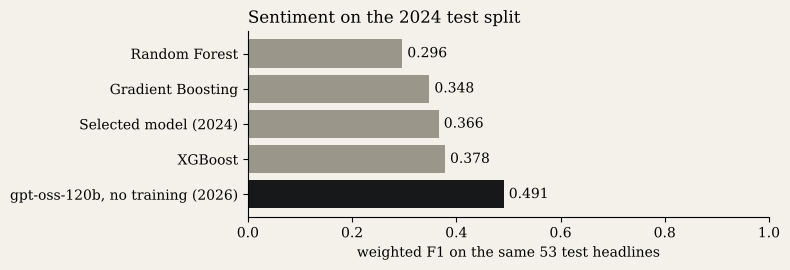

In [4]:
base = R["sentiment"]["baseline_2024"]
names = ["Random Forest", "Gradient Boosting", "Selected model (2024)", "XGBoost", "gpt-oss-120b, no training (2026)"]
vals = [base["Random Forest"], base["Gradient Boosting"], base["Selected model (2024)"], base["XGBoost"], f_split]
fig, ax = plt.subplots(figsize=(8, 2.8))
bars = ax.barh(names, vals, color=[GREY] * 4 + [INK])
for b, v in zip(bars, vals): ax.text(v + 0.01, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center")
ax.set_xlim(0, 1); ax.set_xlabel("weighted F1 on the same 53 test headlines"); ax.invert_yaxis()
ax.set_title("Sentiment on the 2024 test split", loc="left"); plt.tight_layout(); plt.show()

**Finding.** On the same 53 headlines the score went from 0.366 (2024 selected model) to 0.491. On all 349 headlines the model scores 0.414.

**How far to trust it.** 53 rows is small: one headline moves weighted F1 by about 0.02, and the all-349 score is lower than the 53-row score, so part of the gap is likely luck of the split. The 2024 models cannot be scored on all 349 because they trained on 70% of them. The confusion matrix shows where the model disagrees with the course's labels: mostly on what counts as neutral.

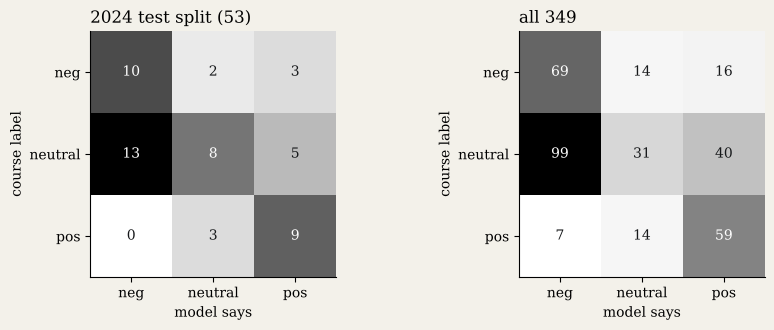

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, (d, title) in zip(axes, [(df[df.id.isin(test_ids)], "2024 test split (53)"), (df, "all 349")]):
    cm = confusion_matrix(d.Label, d.pred, labels=[-1, 0, 1])
    ax.imshow(cm, cmap="Greys")
    for i in range(3):
        for j in range(3): ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else INK)
    ax.set_xticks(range(3), ["neg", "neutral", "pos"]); ax.set_yticks(range(3), ["neg", "neutral", "pos"])
    ax.set_xlabel("model says"); ax.set_ylabel("course label"); ax.set_title(title, loc="left")
plt.tight_layout(); plt.show()

## 3. The check on 18 weekly briefs

For each week the writer model returns claims; each claim cites headline ids or price figures. Then, per claim: the checker model (a different family) judges it against the cited headlines, the sandbox's recomputed price figures are compared with any numbers, and `decide.py` keeps or removes it.

108 claims written, 100 shown, 8 removed (7.4%); all weeks complete: True


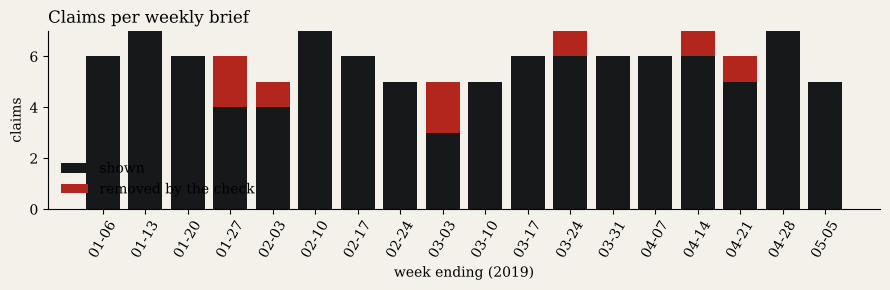

,claims removed
not_supported,5
quote_not_found,3


In [6]:
S = R["briefs_summary"]
print(f"{S['claims_written']} claims written, {S['claims_kept']} shown, {S['claims_removed']} removed ({S['claims_removed'] / S['claims_written']:.1%}); all weeks complete: {R['briefs_run']['complete']}")
pw = pd.DataFrame(S["per_week"]); pw["kept"] = pw.written - pw.removed
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(pw.week.str[5:], pw.kept, color=INK, label="shown"); ax.bar(pw.week.str[5:], pw.removed, bottom=pw.kept, color=RED, label="removed by the check")
ax.set_ylabel("claims"); ax.set_xlabel("week ending (2019)"); ax.legend(frameon=False); ax.set_title("Claims per weekly brief", loc="left")
plt.xticks(rotation=60); plt.tight_layout(); plt.show()
pd.Series(S["removed_by_reason"], name="claims removed").to_frame()

**Every removed claim, with the reason.** These are the 8 a reader of the unchecked briefs would have been shown as fact.

In [7]:
rows = [{"week": b["week"], "claim": c["text"], "reason": c["reason"], "detail": c["detail"]}
        for b in R["briefs"] for c in b["claims"] if not c["keep"]]
pd.DataFrame(rows)

,week,claim,reason,detail
0,2019-01-27,"Apple’s stock rose after the release of better‑than‑expected fourth‑quarter results, as noted in a broader market rally.",not_supported,The evidence does not specify that Apple's stock rise was due to better-than-expected fourth-quarter results or link it to a broader market rally; it only mentions the rise without attributing it ...
1,2019-01-27,"Apple’s share price opened the week at $39.10, reached a high of $39.53, fell to a low of $37.92, and closed the week at $38.13, a change of –2.48%.",not_supported,"The claim states a change of -2.48%, but the evidence shows a change of -2.49%."
2,2019-02-03,During the week the highest price reached $42.25 and the lowest price was $38.42.,not_supported,"The evidence states the low price was 38.42, but the claim says the lowest price was $38.42, which matches; however, the evidence says the week opened at 38.95 and closed at 38.17, meaning the low..."
3,2019-03-03,"Spotify entered the Indian market, joining Apple, Google, Amazon and Reliance as a major music‑streaming competitor.",quote_not_found,"Quoted: “Spotify, the world's leading paid music streaming service, entered the Indian market on Tuesday. Apple, Google, Amazon, ”"
4,2019-03-03,"President Trump’s progress in trade talks with China lifted major U.S. indexes, a development that could benefit Apple’s supply chain.",not_supported,"The evidence does not mention Apple or its supply chain, so the claim about benefits to Apple’s supply chain is not supported."
5,2019-03-24,"During the week, Apple’s stock opened at $46.45, closed at $46.37, a change of –0.17%.",not_supported,"The claim states a change of -0.17%, but the evidence shows a change of -0.16%."
6,2019-04-14,Oprah Winfrey and Prince Harry are partnering on an Apple documentary slated for release next year to promote mental health awareness.,quote_not_found,"Quoted: “Oprah Winfrey and Prince Harry have partnered to create an Apple documentary, set for combust next year, aimed at promot”"
7,2019-04-21,Apple removed the TikTok app from its App Store in India after a state court order mandated its deletion.,quote_not_found,"Quoted: “Chinese video-sharing app Tik游戏副本, owned by Bytedance Technology, has been removed from Google's Play Store and Apple's ”"


**Findings.**

- 8 of 108 claims (7%) were removed: 5 where the checker found the cited news did not say what the claim says, 3 where the checker said "supported" but the passage it quoted was not in the cited headline, so the code overruled it.
- 0 claims cited a headline that did not exist and 0 price figures differed from the sandbox. Both checks ran on every claim; the writer simply got those right in this run.
- Not measured: how many wrong claims passed. That needs a person to label all 108.

**The sandbox's figures** (one run of plain Python in Otari's sandbox, no model):

In [8]:
pd.DataFrame({b["week"]: b["figures"] for b in R["briefs"]}).T.head(6)

,week_open,week_close,week_high,week_low,week_change_pct
2019-01-06,41.74,46.42,47.92,41.48,11.21
2019-01-13,50.79,62.57,63.98,50.16,23.19
2019-01-20,37.71,37.90,39.47,37.30,0.50
2019-01-27,39.10,38.13,39.53,37.92,-2.49
2019-02-03,38.95,38.17,42.25,38.42,-2.00
2019-02-10,47.77,49.71,53.16,47.76,4.06


## 4. What went wrong in the first run

In the first run the checker was given the raw daily price rows. It rejected price claims whose figures the sandbox had confirmed, because it was doing the arithmetic itself. The fix: the checker now receives the sandbox's figures as its evidence.

In [9]:
F = json.load(open("runs/first_run_results.json"))
first = collections.Counter((c["kind"], c["reason"]) for b in F["briefs"] for c in b["claims"] if not c["keep"])
now = collections.Counter((c["kind"], c["reason"]) for b in R["briefs"] for c in b["claims"] if not c["keep"])
pd.DataFrame({"first run": first, "final run": now}).fillna(0).astype(int)

first run  final run
price not_supported           16          3
news  not_supported            2          2
      quote_not_found          4          3
price no_verdict               1          0

## 5. What the gateway did

Read from the call log (`runs/otari_calls.jsonl`: one line per request, no prompt text, no key).

In [10]:
calls = [json.loads(l) for l in open("runs/otari_calls.jsonl") if l.strip()]
c = pd.DataFrame(calls)
ok = c[(c.path == "/chat/completions") & (c.status == 200)]
display(ok.groupby("model_served").agg(calls=("purpose", "size"), cost_usd=("cost_usd", "sum"), jobs=("purpose", lambda s: ", ".join(sorted(set(s))))))
print("sandbox runs:", ((c.path == "/code/execute") & (c.status == 200)).sum(), "| fetches:", ((c.path == "/fetch") & (c.status == 200)).sum(),
      "| fallbacks:", int(c.fallback.fillna(False).sum()), "| guardrail blocks:", (c.code == "guardrail_violation").sum(), "| budget refusals:", (c.code == "budget_exceeded").sum())
print("key:", R["otari"]["key_budget"]["limits"][0]["used_usd"], "used of", R["otari"]["key_budget"]["limits"][0]["limit_usd"])

,calls,cost_usd,jobs
model_served,,,
Qwen/Qwen3-235B-A22B-Instruct-2507,156,0.010487,check
openai/gpt-oss-120b,854,0.037222,"classify, fallback drill, tone+guardrail, write, write live"


sandbox runs: 2 | fetches: 4 | fallbacks: 2 | guardrail blocks: 2 | budget refusals: 2
key: 0.160595 used of 1.5


In [11]:
D = R["drills"]
print("FALLBACK DRILL :", D["fallback"]["main_model"], "->", D["fallback"]["served_by"], "| attempts", D["fallback"]["attempts"], "| Otari-Fallback", D["fallback"]["otari_fallback"])
print("GUARDRAIL DRILL:", repr(D["guardrail"]["text"]), "->", D["guardrail"]["status"], D["guardrail"]["code"])
print("BUDGET DRILL   :", D["budget"]["stopped"]["detail"][:120], "...")
print("                 weeks missing:", len(D["budget"]["summary"]["weeks_missing"]), "| run marked complete:", D["budget"]["complete"])

FALLBACK DRILL : mistralai/mistral-nemo-instruct-2407 -> openai/gpt-oss-120b | attempts 2 | Otari-Fallback True
GUARDRAIL DRILL: 'Investors should buy Apple shares now, before the next earnings report.' -> 403 guardrail_violation
BUDGET DRILL   : API key has $1.400143 of budget remaining, less than this request's estimated cost of $9.600243. The estimate assumes 16 ...
                 weeks missing: 13 | run marked complete: False


## 6. This week, on news no model has memorised

Headlines and five days of prices fetched through Otari, then the same pipeline.

In [12]:
L = R["live"]
print(L["fetched_at"], "|", len(L["headlines"]), "headlines |", len(L["prices"]), "price rows | figures:", L["brief"]["figures"])
pd.DataFrame([{"claim": c["text"], "kind": c["kind"], "shown": c["keep"], "reason": c["reason"] or ""} for c in L["brief"]["claims"]])

2026-11-12T00:08:24Z | 12 headlines | 5 price rows | figures: {'week_open': 353.89, 'week_close': 355.63, 'week_high': 355.9, 'week_low': 338.3, 'week_change_pct': 0.49}


,claim,kind,shown,reason
0,"Apple shares have surged in 2026, easily outperforming the Nasdaq‑100 index.",news,True,
1,Analysts say Apple’s stock looks expensive heading into fiscal 2027 despite strong growth prospects.,news,True,
2,"The iPhone Duo is expected to unlock a decade of potential for Apple, fueling its best year since 2024.",news,False,not_supported
3,Apple’s shares slid about 4% after the company guided a lower gross‑margin range for the December quarter.,news,True,
4,Apple hit a new record price as the Nasdaq rallied on strong AI‑related earnings.,news,True,
5,"Google integrated its Gemini AI voice assistant into Apple CarPlay, enabling hands‑free two‑way conversations.",news,True,
6,"Apple’s stock opened the week at $353.89 and closed at $355.63, a gain of about 0.5 %.",price,True,
7,During the week the highest price reached was $355.90 and the lowest was $338.30.,price,True,


## What this adds up to

- **For a reader or publisher of model-written summaries:** in this run about 1 claim in 14 had no support in the news it cited. The 2024 version showed all of them. Countersign shows which ones and why, at a cost of about $0.05 for 18 briefs.
- **For sentiment:** a better score than the 2024 pipeline on its own test rows, with no training data and no GPU, with the caveats in section 2.
- **Limits:** one dataset, one company, 18 weeks; the check's misses are unmeasured; the price columns are the course dataset's and are not always consistent with real prices.